# Exploratory Data Analysis v3: release dates and time-adjusted popularity

**IS428 Visual Analytics · Group 7 · *Engineering the Ultimate Audio Dopamine Trap***

> **Guiding question:** *How are audio features associated with track popularity across Spotify and YouTube?*

> **Feedback this notebook answers:** *Streams, views, likes and comments accumulate over the years, so an older song has simply had more time to collect them. Having the release date should remove this confounding factor.*

The v2 notebook cleaned the data and compared popularity across platforms and audio features, but it had no notion of **time**. This version starts from `dataset/spotify_youtube_release_date.csv`: the v2 clean table plus each song's **first release date** and age-adjusted popularity measures, all added by `scripts/add_release_dates.py`. It checks how reliable those dates are, whether they remove the time confounder, and which v2 findings change once they do.

| # | Question | Section |
|---|---|---|
| Q1 | What do the release-date columns add, and how complete and reliable are they? | §2 |
| Q2 | Does song age confound popularity, and is it linked to the audio features? | §3 |
| Q3 | How should streams, views, likes and comments be aggregated over time to remove it? | §4 |
| Q4 | Which v2 findings change once age is controlled? | §5 |
| Q5 | Does the new CSV address the feedback, and what is still missing? | §6 |

The CSV is also the Tableau-ready table: every column used here is in it.

**How to read the charts:** as in v2, Spotify is always **blue**, YouTube always **orange** and grey marks are platform-neutral. Popularity counts use a **log10 scale** (6 = one million, 9 = one billion), and correlations are **Spearman's ρ**.

## 1. Setup

Same libraries, palette and helpers as v2. The file is found by walking up from the working directory, so the notebook runs from either `notebooks/` or the repo root.

In [1]:
import re
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message=r"\s*Pyarrow will become a required dependency", category=DeprecationWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats


def _format_float(x):
    # Readable floats in tables: 1,234,567 | 12.35 | 0.0442
    if abs(x) >= 1000:
        return f"{x:,.0f}"
    if abs(x) >= 1 or x == 0:
        return f"{x:.2f}"
    return f"{x:.3g}"


pd.set_option("display.float_format", _format_float)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dataset" / "spotify_youtube_release_date.csv").exists())
DATA_PATH = ROOT / "dataset" / "spotify_youtube_release_date.csv"

AUDIO_FEATURES = ["Danceability", "Energy", "Loudness", "Speechiness", "Acousticness",
                  "Instrumentalness", "Liveness", "Valence", "Tempo", "Duration_ms"]
FEATURE_LABELS = {"Duration_ms": "Duration (min)", "Loudness": "Loudness (dB)", "Tempo": "Tempo (BPM)"}
TIER_LABELS = ["Q1 (Low)", "Q2", "Q3", "Q4 (Top)"]
TOP_TIER = TIER_LABELS[-1]

COLLECTION_DATE = pd.Timestamp("2023-02-07")   # the day streams and views were counted (Kaggle)
SPOTIFY_LAUNCH = pd.Timestamp("2008-10-07")    # no song can have streamed before this
YOUTUBE_LAUNCH = pd.Timestamp("2005-12-15")    # public launch of YouTube

# Age bands used throughout: finer where popularity changes fastest (the first years)
AGE_BANDS = [0, 0.25, 0.5, 1, 2, 3, 5, 8, 12, 20, np.inf]
AGE_LABELS = ["<3 mo", "3–6 mo", "6–12 mo", "1–2 y", "2–3 y", "3–5 y", "5–8 y", "8–12 y", "12–20 y", "20+ y"]

print("Data file:", DATA_PATH)

Data file: C:\Users\wasd0\OneDrive\Documents\SMU\Y4S1\VA\Project\Visual-Analytics-Group-7\dataset\spotify_youtube_release_date.csv


In [3]:
# Colours come from a validated reference palette. Blue and orange stay distinct under
# protanopia/deuteranopia (CVD ΔE 24.7); Spotify-green vs YouTube-red would not.
SPOTIFY, YOUTUBE = "#2a78d6", "#eb6834"
PLATFORM_COLOURS = {"Spotify": SPOTIFY, "YouTube": YOUTUBE}
NEUTRAL, MUTED, FAINT = "#52514e", "#898781", "#c3c2b7"
INK, SURFACE, GRID, MIDPOINT = "#0b0b0b", "#fcfcfb", "#e1e0d9", "#f0efec"

installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
ui_font = next((f for f in ["Segoe UI", "Helvetica Neue", "Arial"] if f in installed_fonts), None)

plt.rcParams.update({
    "font.family": [f for f in (ui_font, "DejaVu Sans") if f],  # DejaVu supplies glyphs such as ♯ and ♭
    "font.size": 10,
    "figure.dpi": 100,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.titlesize": 13, "figure.titleweight": "bold",
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": NEUTRAL,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": FAINT, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": FAINT, "ytick.color": FAINT, "xtick.labelcolor": NEUTRAL, "ytick.labelcolor": NEUTRAL,
    "legend.frameon": False,
    "lines.linewidth": 2, "lines.markersize": 7, "lines.solid_capstyle": "round",
    "patch.edgecolor": SURFACE,
})


def human(n):
    """1_234_567 -> "1.2M": readable counts for labels and tables."""
    for unit, size in (("B", 1e9), ("M", 1e6), ("K", 1e3)):
        if abs(n) >= size:
            return f"{n / size:.1f}".rstrip("0").rstrip(".") + unit
    return f"{n:,.0f}"


def human_col(series):
    return series.map(lambda v: human(v) if pd.notna(v) else "–")


def log_axis(axis):
    """Integer ticks on a log10(x + 1) axis, labelled in readable units (0 -> 0, 6 -> 1M)."""
    axis.set_major_locator(mticker.MultipleLocator(1))
    axis.set_major_formatter(mticker.FuncFormatter(lambda v, _: "0" if v == 0 else human(10 ** v) if v > 0 else ""))


def times_axis(axis):
    """A log10-ratio axis labelled as multiples: -1 -> 0.1×, 0 -> 1×, 0.3 -> 2×."""
    axis.set_major_locator(mticker.FixedLocator(np.log10([0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10])))
    axis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{10 ** v:g}×"))


def fig_title(fig, text):
    fig.suptitle(text, x=0.01, ha="left")


def band_line(ax, x, mid, low, high, colour, label=None):
    """Median line with an interquartile band."""
    ax.fill_between(x, low, high, color=colour, alpha=0.15, linewidth=0)
    ax.plot(x, mid, color=colour, marker="o", markeredgecolor=SURFACE, markeredgewidth=1.5, label=label)


def by_age(data, col):
    """Median and interquartile range of a column per age band."""
    g = data.groupby("age_band", observed=False)[col]
    return pd.DataFrame({"median": g.median(), "q1": g.quantile(0.25), "q3": g.quantile(0.75), "n": g.count()})


def age_ticks(ax, rotate=True):
    ax.set_xticks(range(len(AGE_LABELS)), AGE_LABELS, rotation=45 if rotate else 0, ha="right" if rotate else "center")
    ax.grid(axis="x", visible=False)

## 2. The release-date columns

### 2.1 What the file contains

In [4]:
df = pd.read_csv(DATA_PATH, parse_dates=["release_date"], float_precision="round_trip")
df["release_year"] = df.release_year.astype("Int64")   # read as float because undated rows are empty
df["age_band"] = pd.Categorical(df.age_band, categories=AGE_LABELS, ordered=True)
for col in ["spotify_tier_age_adj", "youtube_tier_age_adj"]:
    df[col] = pd.Categorical(df[col], categories=TIER_LABELS, ordered=True)
DATE_COLUMNS = ["release_date", "release_date_precision", "release_date_source", "release_date_confidence",
                "release_year", "years_since_release"]
AGE_COLUMNS = ["age_band", "stream_vs_age", "views_vs_age", "likes_vs_age", "comments_vs_age",
               "spotify_tier_age_adj", "youtube_tier_age_adj"]
RANK_COLUMNS = [c for c in df.columns if c.endswith("_rank")]
print(f"{len(df):,} tracks × {df.shape[1]} columns: the 53 v2 columns, {len(DATE_COLUMNS)} date columns, "
      f"{len(AGE_COLUMNS)} age-adjusted columns and {len(RANK_COLUMNS)} rank columns for Tableau")
df[["Artist", "Track", "Album_type"] + DATE_COLUMNS].sample(5, random_state=3)

18,847 tracks × 80 columns: the 53 v2 columns, 6 date columns, 7 age-adjusted columns and 14 rank columns for Tableau


,Artist,Track,Album_type,release_date,release_date_precision,release_date_source,release_date_confidence,release_year,years_since_release
18009,Tems,Essence (feat. Tems),album,2020-10-28,day,musicbrainz_song,confirmed,2020,2.28
17865,Lil Nas X,Rodeo,single,2019-06-21,day,wikidata_song,confirmed,2019,3.63
1352,Scorpions,Wind Of Change,album,1990-07-01,year,musicbrainz_album,confirmed,1990,32.61
9730,Harshdeep Kaur,Zaalima,compilation,2017-01-24,day,musicbrainz_song,confirmed,2017,6.04
1135,Jennifer Lopez,Dance Again,compilation,2012-04-01,day,musicbrainz_song,confirmed,2012,10.85


| Column | Meaning |
|---|---|
| `release_date` | The song's first release (§2.3 explains how it is chosen) |
| `release_date_precision` | `day`, `month` or `year`; year-only dates are set to 1 July and month-only dates to the 15th |
| `release_date_source` | Where the date came from: `wikidata_song`, `musicbrainz_album`, `wikidata_album`, `musicbrainz_song` or `deezer` |
| `release_date_confidence` | `confirmed` (a second source agrees within 6 months), `single source`, or `edition date only` (only Deezer's edition date: the song may be older) |
| `release_year`, `years_since_release` | Year of release, and years from release to the collection date (7 Feb 2023) |
| `age_band` | Years since release, grouped: <3 mo, 3–6 mo, …, 12–20 y, 20+ y |
| `stream_vs_age`, `views_vs_age`, `likes_vs_age`, `comments_vs_age` | log10 count minus the median of songs in the same age band: 0 = typical for its age, +1 = 10× a typical song of the same age (§4) |
| `spotify_tier_age_adj`, `youtube_tier_age_adj` | Popularity quartile within the song's age band (§4) |
| `<column>_rank` | Percentile rank (0–1) of the 10 audio features and of `log_stream`, `stream_vs_age`, `log_views` and `views_vs_age`. Tableau has no Spearman function, but Spearman's ρ is the ordinary correlation of ranks, so `CORR()` of two rank columns gives it |

YouTube upload dates are not in the file: they need a YouTube API key, and the script only adds `youtube_published_at` when they have been fetched.

### 2.2 Coverage: which songs have a date?

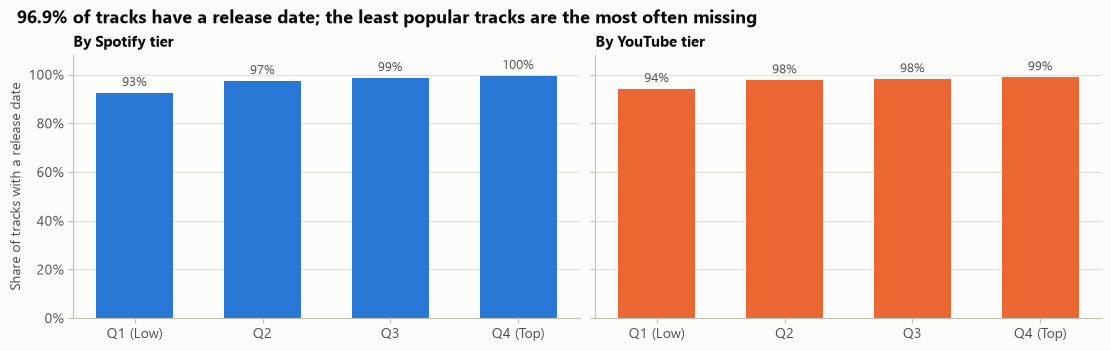

,album,single,compilation,spoken word,all tracks
tracks,"13,954","4,204",689,122,"18,847"
with a release date,98%,95%,95%,80%,97%


In [5]:
has_date = df.release_date.notna()
coverage = {
    "Spotify tier": has_date.groupby(df.spotify_tier).mean(),
    "YouTube tier": has_date[df.yt_primary].groupby(df.youtube_tier[df.yt_primary]).mean(),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), layout="constrained", sharey=True)
for ax, (name, share), colour in zip(axes, coverage.items(), PLATFORM_COLOURS.values()):
    bars = ax.bar(share.index.astype(str), share.values, color=colour, width=0.6)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in share.values], padding=3, color=NEUTRAL, fontsize=9)
    ax.set_title(f"By {name}")
    ax.set_ylim(0, 1.08)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Share of tracks with a release date")
fig_title(fig, f"{has_date.mean():.1%} of tracks have a release date; the least popular tracks are the most often missing")
plt.show()

groups = {**{t: df.Album_type.eq(t) for t in ["album", "single", "compilation"]},
          "spoken word": df.is_spoken_word, "all tracks": pd.Series(True, index=df.index)}
pd.DataFrame({name: {"tracks": f"{mask.sum():,}", "with a release date": f"{has_date[mask].mean():.0%}"}
              for name, mask in groups.items()})

**Observations**

- **18,256 of the 18,847 tracks (96.9%) have a release date.** Albums are the best covered (98%), then singles and compilations (95%). Spoken word is the worst (80%).
- **The 591 missing dates are not random.** 93% of Spotify's least popular tier has a date, against 100% of its top tier (94% vs 99% on YouTube). The gaps are mostly classical recordings, sleep and nature sounds (*Sleepy Penguin*, *Ocean Sounds*) and small releases that none of the sources list.
- The gap is small, so it barely affects the age analyses below, which lean very slightly toward popular tracks. Undated tracks keep their rows in the CSV, with empty age columns.

### 2.3 Where the dates come from, and how sure they are

Streaming services date the **edition** they carry, and for older songs that is usually a remaster or a compilation. Billy Joel's *Movin' Out* (1977) is on Deezer only as the 2009 *Legacy Edition* and a 2001 best-of, and AC/DC's *Back in Black* (1980) only in 2014 editions. Taking the earliest Deezer edition cannot fix this, because the original edition isn't there.

The script therefore asks four **first-release** sources, which record the original date across all editions. MusicBrainz is read from its full database dump (`scripts/musicbrainz_dump.py`), so every song is looked up:

1. `wikidata_song`: the song's own Wikidata entry;
2. `musicbrainz_album`: the MusicBrainz release group (all editions) of the Spotify track's album;
3. `wikidata_album`: the album's Wikidata entry;
4. `musicbrainz_song`: the earliest official release containing the recording in MusicBrainz (bootlegs excluded; a remix or live track only matches the same named version).

Rules for combining them:
- **The earliest date that a second source confirms within 6 months wins**, so one wrong match can't decide it (MusicBrainz lists a 1978 demo of *Billie Jean*; nothing confirms it, so the 1982 date wins). If nothing is confirmed, the first available source in the list above is used, and Deezer's edition date only as a last resort.
- **An edition date is an upper limit.** Deezer's edition is a real release of the song, so a first-release date more than a year later is discarded (that source is missing the early releases).
- Album dates are not used for compilations, re-recordings or remix/live tracks on studio albums.
- **1 January counts as year-only** from every source (it almost always stands for "year unknown"); year-only dates are placed on 1 July.

The window (6 months) and the rules were chosen by scoring alternatives against the hand check in §2.4 and against 114 songs with documented release dates, including the examples from the data audit.

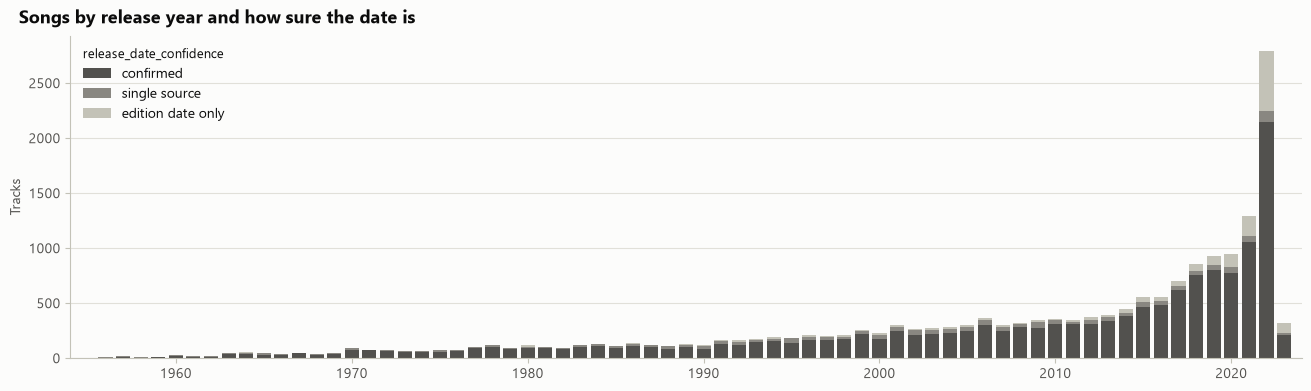

release_date_confidence,confirmed,single source,edition date only,tracks
release_year,,,,
before 1980,0.83,0.17,0.01,1332
1980–1999,0.8,0.16,0.04,3059
2000–2009,0.82,0.13,0.06,2993
2010–2014,0.87,0.08,0.05,1921
2015–2023,0.82,0.05,0.13,8951


release_date_confidence,confirmed,single source,edition date only,all
release_date_source,,,,
deezer,1303,0,1606,2909
musicbrainz_album,6901,201,0,7102
musicbrainz_song,2736,1287,0,4023
wikidata_album,1427,76,0,1503
wikidata_song,2613,106,0,2719
all,14980,1670,1606,18256


In [6]:
CONFIDENCE_ORDER = ["confirmed", "single source", "edition date only"]
CONFIDENCE_COLOURS = dict(zip(CONFIDENCE_ORDER, [NEUTRAL, MUTED, FAINT]))
year_bins = np.arange(1955, 2024)
counts = (df[has_date].groupby(["release_year", "release_date_confidence"]).size().unstack(fill_value=0)
          .reindex(index=year_bins, columns=CONFIDENCE_ORDER).fillna(0).astype(int))

fig, ax = plt.subplots(figsize=(13, 3.8), layout="constrained")
bottom = np.zeros(len(counts))
for level in CONFIDENCE_ORDER:
    ax.bar(counts.index, counts[level], bottom=bottom, width=0.8, color=CONFIDENCE_COLOURS[level], label=level)
    bottom += counts[level].to_numpy()
ax.set_ylabel("Tracks")
ax.set_xlim(1954, 2024)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", title="release_date_confidence", title_fontsize=9, alignment="left")
fig_title(fig, "Songs by release year and how sure the date is")
plt.show()

era = pd.cut(df.release_year.astype(float), [0, 1979, 1999, 2009, 2014, 2023],
             labels=["before 1980", "1980–1999", "2000–2009", "2010–2014", "2015–2023"])
display(pd.crosstab(era, df.release_date_confidence, normalize="index").reindex(columns=CONFIDENCE_ORDER)
        .assign(tracks=era.value_counts()).round(2))
pd.crosstab(df.release_date_source, df.release_date_confidence, margins=True, margins_name="all").reindex(
    columns=CONFIDENCE_ORDER + ["all"])

**Observations**

- **82% of dates are confirmed by two sources** (14,980), 9% come from a single first-release source (1,670), and 9% from Deezer's edition date alone (1,606).
- **Old songs are now confirmed as often as new ones:** 83% of pre-1980 songs and 80% of 1980–1999 songs are confirmed. Only 1% of pre-1980 songs depend on an edition date alone. Edition-only dates are concentrated in 2015–2023 (13%): recent songs that MusicBrainz and Wikidata don't list yet. For a recent song, the edition date is usually the real release, because there is no remaster yet.
- **Compared with Deezer alone, 4,760 tracks (28%) get a different year.** Almost all of them (4,639) move earlier, by a median of 10 years. Pre-1990 songs grow from 866 to 2,438, and 1,154 tracks that Deezer couldn't date now have a date.
- **Songs on the same album now mostly agree.** Of 12,349 artist–album pairs, 10,878 have a single date. 164 span more than 3 years, mostly best-ofs (Spotify labels many of them "album"), where the songs really do come from different years.
- **Precision:** 12,165 dates are exact days, 370 months and 5,721 years only. A year-only date is placed on 1 July, so its age can be off by up to half a year. That matters only in the youngest age bands.
- **No 1 January placeholders remain** labelled as exact days.

### 2.4 Hand check: 50 random tracks against their documented first release

Fifty tracks were drawn at random from all 18,847 (`random_state=2026`) and each was compared with its documented first release: the first release of **that exact recording or version** (a remix counts from the remix's release, a live version from the live release). The source for each is in the table. Four could not be verified (a classical recording, a lo-fi cover, and two recent live and sped-up versions) and are left out. `deezer_old` is the date in the first version of this file, which used Deezer alone.

In [7]:
HAND_CHECK = [  # (Spotify track id, date in the first version of the file, true first-release year(s), source)
    ("7CpXFEjLntpr4GdOhTtFEv", "2022-11-29", "2022", "single 29 Nov 2022 (Revolt, Rolling Stone)"),  # Nas – One Mic, One Gun
    ("5Q8SPijJts3lV4fcmCrZXp", "1983-10-28", "1988", "remix album Once More into the Bleach, 5 Dec 1988 (Wikipedia)"),  # Blondie – Heart Of Glass - Remix
    ("2RxC2peY3FtrurYmbbmanr", "2020-05-01", "2020", "Banda MS feat. Snoop Dogg single, 2020"),  # Snoop Dogg – Qué Maldición
    ("3qOkkP9JLltoUvaLjEXTmW", "2019-05-31", "2018", "single 24 Oct 2018 (Wikipedia: Sensational)"),  # Yung Gravy – Gravy Train
    ("6G12ZafqofSq7YtrMqUm76", "2022-10-19", "2022", "Shakira & Ozuna single, 19 Oct 2022"),  # Ozuna – Monotonía
    ("3RjVR6vjFDotAeSTGSfmLT", "2022-10-14", "", "could not verify the live version"),  # Murilo Huff – Boca Enganada - Ao Vivo
    ("4fvriHKtGQhSBBKOi6z4Tg", "2012-11-05", "2012", "album 2012 (retailer listing)"),  # Simone Sommerland – La-Le-Lu
    ("7H3ojI1BsVy0dEJENqMt1k", "2000-01-11", "2000", "Lovers Rock / single, 2000"),  # Sade – By Your Side
    ("5a3rLTbh7L7lBj5cflW3sf", "2011-04-05", "2011", "American Tragedy, Apr 2011"),  # Hollywood Undead – Comin’ In Hot
    ("5mEqD00bdFcsiVd0MfvEeF", "2016-08-24", "2016", "Your Name. soundtrack, Aug 2016"),  # RADWIMPS – Dream lantern
    ("41nT1Sp6ChR65FbsdLlFHW", "2001-01-01", "2001", "Survivor / single, 2001"),  # Destiny's Child – Bootylicious
    ("4ztwMHfPZhPoruZdBbgriM", "1992-08-04", "1978", "Natural High, 1978"),  # Commodores – Three Times A Lady
    ("5PZAbR6JHYYV9xp5gv0XES", "2022-06-17", "2022", "about June 2022 (Metrópoles, Aug 2022: under 3 months old)"),  # Zé Felipe – Bandido
    ("4q6dqyGM25sKFU8nYAGRe4", "2014-01-03", "2013", "single 17 Sep 2013 (Wikipedia)"),  # Kid Ink – Show Me (feat. Chris Brown)
    ("4Of7rzpRpV1mWRbhp5rAqG", "2019-05-17", "2017", "single, Mar 2017"),  # Lewis Capaldi – Bruises
    ("7ngdkrVQPgP3AoIxUrTpHT", "2014-03-18", "2014", "single 20 Feb 2014 (Wikipedia); leaked Dec 2013"),  # YG – Who Do You Love?
    ("7zjEyeBsaw9gV0jofJLfOM", "2021-10-15", "2021", "Young Thug, Punk, Oct 2021"),  # A$AP Rocky – Livin It Up (with Post Malone & A$AP Rocky)
    ("6FvSS3Goz7OC8oCC2eWqe8", "2021-06-23", "2021", "Tesher x Jason Derulo, Jun 2021"),  # Jason Derulo – Jalebi Baby (Tesher x Jason Derulo)
    ("3WMj8moIAXJhHsyLaqIIHI", "2022-04-22", "2022", "single 22 Apr 2022"),  # Zach Bryan – Something in the Orange
    ("6Pt5ky10RuJCMwAQi8xJFy", "2022-12-09", "2022", "triple j Like A Version, Nov 2022"),  # Flume – Shooting Stars - triple j Like A Version
    ("2z2HMfMK1vR4BZLL6JIWgV", "2005-09-20", "2005", "Tu Sombra, 2005 (fan site; weak)"),  # Pesado – Te quiero, te amo
    ("4uVjbl6daCwjhDur7qLddu", "2002-03-19", "2002", "No Pads, No Helmets...Just Balls, 2002"),  # Simple Plan – I'd Do Anything
    ("25fcj6d2W1l8DQL11Czdzb", "2018-10-17", "2018", "single Oct 2018"),  # Brandi Carlile – Party of One (feat. Sam Smith)
    ("3jjujdWJ72nww5eGnfs2E7", "2019-12-13", "2019", "single/album Dec 2019"),  # Harry Styles – Adore You
    ("7tTPXjxNFjij4xzGeO3KLt", "2018-09-07", "2018", "Spotify Singles: Christmas, Nov 2018 (Spotify newsroom)"),  # Joan Jett & the Blackhearts – Little Drummer Boy - Recorded at Spotify Studios NYC
    ("68BWeLhmc7G805o8KPUWWm", "2022-09-02", "", "could not verify the sped-up version"),  # DVRST – Dream Space - Sped Up
    ("6U03Orwr5Dxt8jahLnQpYV", "", "1963", "Samba Esquema Novo, 1963"),  # Jorge Ben Jor – Mas, Que Nada!
    ("4SnTf4ixVZCfQtxHNhky0T", "2002-06-04", "2001|2002", "album Genesis Nov 2001 / single 12 Feb 2002 (Wikipedia)"),  # Busta Rhymes – Pass The Courvoisier Part II (feat. P. Diddy & Pharrell) - Remix
    ("59dMMxNmcPXPKa4S0vYi1j", "", "", "could not verify (lo-fi cover)"),  # Kato – Pokémon Theme Lofi
    ("77GQOehkChjV2fUWV4OmNf", "", "2013", "Taking Off!, 2013"),  # The Wiggles – Do the Propeller!
    ("56Ta1O7Jxxpjnc6cWdDKUo", "2020-02-17", "2020", "Reik, Farruko & Camilo, Feb 2020"),  # Reik – Si Me Dices Que Sí
    ("31JhTEAWmmhZIZTm40pQZr", "1998-06-26", "1998", "single Feb 1998"),  # Scooter – How Much Is The Fish?
    ("3FXo3xKG3aYV3hvdRzUY61", "2005-12-08", "2002", "Bocas Ordinárias, Nov/Dec 2002 (Wikipedia, AllMusic)"),  # Charlie Brown Jr. – Só Por Uma Noite
    ("0LCDbXTaYlxC7XLmCkP9BI", "", "2022", "Apr 2022 (Amar Ujala)"),  # Shilpi Raj – Le Le Aayi Coca Cola
    ("7vPHiwgCOAjSBRjAirbMvS", "1986-11-10", "1986", "The Moon and the Melodies, Nov 1986"),  # Cocteau Twins – Sea, Swallow Me
    ("3zLTPuucd3e6TxZnu2dlVS", "2013-08-30", "", "classical work (1810); the recording's date is unknown"),  # Ludwig van Beethoven – Bagatelle No. 25 in A Minor, WoO 59 "Für Elise"
    ("5ZZm2yxaR7HG9KeGPKqVW8", "", "1985", "Saagar soundtrack, 1985"),  # Kishore Kumar – Saagar Jaisi Aankhonwali - Saagar / Soundtrack Version
    ("3YU9X8ryOR20beT7wOlDIJ", "2007-01-29", "1970", "single 'Eighteen', Nov 1970"),  # Alice Cooper – I'm Eighteen
    ("4mOmWSdTmf6fSAibGWCKp7", "2015-04-07", "2015", "O Kadhal Kanmani soundtrack, 2015"),  # Jonita Gandhi – Mental Manadhil
    ("6m84TzSTM5nbwZxIxkYHz6", "2021-04-22", "2021", "Tudo em Paz, 22 Apr 2021 (uai.com.br)"),  # Jorge & Mateus – Namorando Com Saudade
    ("0yvPEnB032fojLfVluFjUv", "2018-07-02", "2017", "single Jul 2017"),  # Demi Lovato – Sorry Not Sorry
    ("0ePiYPlCq3dhwfAjUttjT2", "2019-06-07", "2019", "Conexión (En Vivo), Jun 2019 (Wikipedia)"),  # María José – Él Era Perfecto - En Vivo
    ("52VIdyKqp1pJRSyUQaxKUA", "1972-01-18", "1972", "Baby I'm-a Want You, Jan 1972"),  # Bread – Everything I Own
    ("3BGfe8GXBE4cCVEvBG10yP", "2023-01-13", "2023", "single 13 Jan 2023 (samfeldt.com)"),  # Sam Feldt – Enough To Drink
    ("1frDifSnJaODOjEuthZ3GJ", "2003-06-10", "2003", "2003 remix single"),  # Nightcrawlers – Push The Feeling On 2003 - Radio Mix (Jerome Isma-Ae Remix)
    ("2YZDh5CecWx0qlFiTvqVQ9", "2021-08-19", "2021", "La Última Promesa, 19 Aug 2021"),  # Justin Quiles – Colorín Colorado
    ("5UY8jf31X2hJkiAualFTyh", "2021-02-26", "2020", "single Feb 2020"),  # Madison Beer – Selfish
    ("3zBhihYUHBmGd2bcQIobrF", "1992-11-06", "1968", "single Jan 1968"),  # Otis Redding – (Sittin' On) the Dock of the Bay
    ("68t93W7Mdwlvia5CpHNsBM", "2017-12-01", "2017", "Trône, Dec 2017"),  # Booba – Petite fille
    ("3q7eDGLKP0MlhqaGEJ3Lg0", "2010-03-26", "2017", "remix single 1 Sep 2017 (chartsinfrance; one source)"),  # Cascada – Everytime We Touch - Fallen Superhero Remix
]

hc = pd.DataFrame(HAND_CHECK, columns=["track_id", "deezer_old", "true_year", "source"])
hc = hc.merge(df.assign(track_id=df.Uri.str.split(":").str[-1])[
    ["track_id", "Artist", "Track", "release_date", "release_date_source", "release_date_confidence"]], on="track_id")
hc = hc[hc.true_year.ne("")]


def year_ok(date, accepted, tolerance=0):
    if pd.isna(date) or date == "":
        return np.nan
    return float(any(abs(int(str(date)[:4]) - int(a)) <= tolerance for a in accepted.split("|")))


rows = {}
for label, col in [("first version (Deezer edition date)", "deezer_old"), ("this file (first-release sources)", "release_date")]:
    exact = pd.Series([year_ok(d, a) for d, a in zip(hc[col], hc.true_year)])
    near = pd.Series([year_ok(d, a, 1) for d, a in zip(hc[col], hc.true_year)])
    rows[label] = {"tracks checked": len(hc), "with a date": int(exact.notna().sum()),
                   "right year": exact.mean(), "within 1 year": near.mean(), "wrong year": 1 - exact.mean(),
                   "more than 1 year off": 1 - near.mean()}
hand_check = pd.DataFrame(rows).T
display(hand_check.round(2))

hc["deezer_old ok"] = [year_ok(d, a) for d, a in zip(hc.deezer_old, hc.true_year)]
hc["now ok"] = [year_ok(d, a) for d, a in zip(hc.release_date, hc.true_year)]
print("Tracks where either version has the wrong year:")
hc[(hc["deezer_old ok"] != 1) | (hc["now ok"] != 1)][
    ["Artist", "Track", "true_year", "deezer_old", "release_date", "release_date_source", "release_date_confidence", "source"]]

,tracks checked,with a date,right year,within 1 year,wrong year,more than 1 year off
first version (Deezer edition date),46.00,42.00,0.74,0.83,0.26,0.17
this file (first-release sources),46.00,45.00,0.91,0.98,0.09,0.02


Tracks where either version has the wrong year:


,Artist,Track,true_year,deezer_old,release_date,release_date_source,release_date_confidence,source
1,Blondie,Heart Of Glass - Remix,1988,1983-10-28,1981-07-01,musicbrainz_song,single source,"remix album Once More into the Bleach, 5 Dec 1988 (Wikip..."
3,Yung Gravy,Gravy Train,2018,2019-05-31,2019-05-31,musicbrainz_album,confirmed,single 24 Oct 2018 (Wikipedia: Sensational)
11,Commodores,Three Times A Lady,1978,1992-08-04,1978-05-10,musicbrainz_song,confirmed,"Natural High, 1978"
13,Kid Ink,Show Me (feat. Chris Brown),2013,2014-01-03,2013-09-17,wikidata_song,confirmed,single 17 Sep 2013 (Wikipedia)
14,Lewis Capaldi,Bruises,2017,2019-05-17,2017-07-01,wikidata_song,confirmed,"single, Mar 2017"
26,Jorge Ben Jor,"Mas, Que Nada!",1963,,1963-07-01,musicbrainz_album,confirmed,"Samba Esquema Novo, 1963"
29,The Wiggles,Do the Propeller!,2013,,2013-02-01,musicbrainz_album,confirmed,"Taking Off!, 2013"
32,Charlie Brown Jr.,Só Por Uma Noite,2002,2005-12-08,2002-07-01,musicbrainz_album,confirmed,"Bocas Ordinárias, Nov/Dec 2002 (Wikipedia, AllMusic)"
33,Shilpi Raj,Le Le Aayi Coca Cola,2022,,NaT,NaN,NaN,Apr 2022 (Amar Ujala)
36,Kishore Kumar,Saagar Jaisi Aankhonwali - Saagar / Soundtrack Version,1985,,1984-07-01,musicbrainz_song,single source,"Saagar soundtrack, 1985"


**Observations**

- **The wrong-year rate fell from 26% to 9%** (11 of 42 dated tracks → 4 of 45). Dates more than a year off fell from 17% to 2%, and 98% are now within a year.
- **The fixes are the older catalogue songs.** For example:
  - *Three Times a Lady*: 1992 → 1978;
  - *I'm Eighteen*: 2007 → 1970;
  - *(Sittin' On) the Dock of the Bay*: 1992 → 1968;
  - *Só Por Uma Noite*: 2005 → 2002.

  Three tracks without a Deezer date (*Mas, Que Nada!*, *Do the Propeller!* and the *Saagar* song) now have one.
- **Four errors remain.** Three are one year off:
  - *Gravy Train* has its album date, not the earlier single's;
  - the *Saagar* song is a year early;
  - *Namorando Com Saudade* takes a Wikidata album date a year early.

  One is far off: Blondie's 1988 *Heart Of Glass* remix gets 1981, from another MusicBrainz recording also labelled a remix.
- **Margin of error:** with 45 tracks, the true wrong-year rate is probably between about 4% and 21%. The rules were also chosen partly on these tracks, so 9% is slightly optimistic. The alternatives scored 87–91%, so the choice matters little.

In [8]:
# Dates too recent for the plays a track already has: a listed date can still be a recent re-release
streams_per_day = df.Stream / (COLLECTION_DATE - df.release_date).dt.days.clip(lower=1)
fast = df.assign(streams_per_day=streams_per_day)[streams_per_day > 3e6]
print(f"{len(fast)} tracks average more than 3M streams a day since their listed release date:")
fast.nlargest(16, "streams_per_day")[["Artist", "Track", "release_date", "Stream", "streams_per_day",
                                      "release_date_source", "release_date_confidence"]].assign(
    Stream=lambda d: human_col(d.Stream), streams_per_day=lambda d: human_col(d.streams_per_day))

24 tracks average more than 3M streams a day since their listed release date:


,Artist,Track,release_date,Stream,streams_per_day,release_date_source,release_date_confidence
17199,NCT DREAM,Glitch Mode,2023-02-07,32.7M,32.7M,musicbrainz_song,single source
11518,Miley Cyrus,Flowers,2023-01-12,283.9M,10.9M,wikidata_song,confirmed
17395,Bizarrap,"Shakira: Bzrp Music Sessions, Vol. 53",2023-01-11,196.8M,7.3M,wikidata_song,confirmed
17452,Fuerza Regida,Se Acabo (En Vivo),2023-01-27,68.6M,6.2M,deezer,edition date only
15725,SZA,Kill Bill,2022-12-09,359.1M,6M,musicbrainz_album,confirmed
17402,Harry Styles,As It Was,2022-03-21,1.9B,5.8M,musicbrainz_song,confirmed
17484,Kim Petras,Unholy (feat. Kim Petras),2022-09-22,771.3M,5.6M,wikidata_song,confirmed
11538,Taylor Swift,Anti-Hero,2022-10-21,530.5M,4.9M,wikidata_song,confirmed
18454,Quevedo,"Quevedo: Bzrp Music Sessions, Vol. 52",2022-07-06,991.5M,4.6M,musicbrainz_album,confirmed
13125,back number,水平線,2023-01-17,95.1M,4.5M,musicbrainz_album,single source


**Observations**

- **24 tracks average more than 3M streams a day. Most of them are genuine launch-week hits:** *Flowers*, *Kill Bill*, *As It Was*, *Unholy*, *Anti-Hero* and the Bizarrap sessions. The older songs that the first version listed with a recent re-release date are gone: PSY's *Gentleman* is now 2013 and *Knockin' On Heaven's Door* 1991.
- **A few dates are still too recent:**
  - NCT DREAM's *Glitch Mode* (released in 2022) and Los Caligaris' *Con Vos* are dated on the collection day, because MusicBrainz lists only "2023" for them and that outranks Deezer's 2022 date;
  - back number's *水平線* was first released in 2020, but is dated 2023.
- A stricter rule (never let a first-release date beat an earlier Deezer date) was tested and rejected. It fixes these but breaks about 90 others, because Deezer sometimes lists a date months too early (*Hey Ya!*: 2002 instead of 2003).

## 3. Is song age a confounder?

A confounder has to be linked to **both** sides of the question: to popularity (§3.1–3.3) and to the audio features (§3.4). All analyses from here on use tracks with a release date. As in v2, Spotify counts one row per track and YouTube one row per video (`yt_primary`), and the feature analyses exclude spoken word. Key results are repeated on **confirmed dates only** as a robustness check.

In [9]:
dated = df[has_date]
music = dated[~dated.is_spoken_word]
music_sp, music_yt = music[music.Stream.notna()], music[music.yt_primary]
reliable = music[music.release_date_confidence.eq("confirmed")]   # robustness subset
print(f"dated {len(dated):,} | music {len(music):,} | music_sp {len(music_sp):,} | music_yt {len(music_yt):,} | "
      f"confirmed dates {len(reliable):,}")

dated 18,256 | music 18,158 | music_sp 17,673 | music_yt 17,323 | confirmed dates 14,932


### 3.1 How popularity changes with age

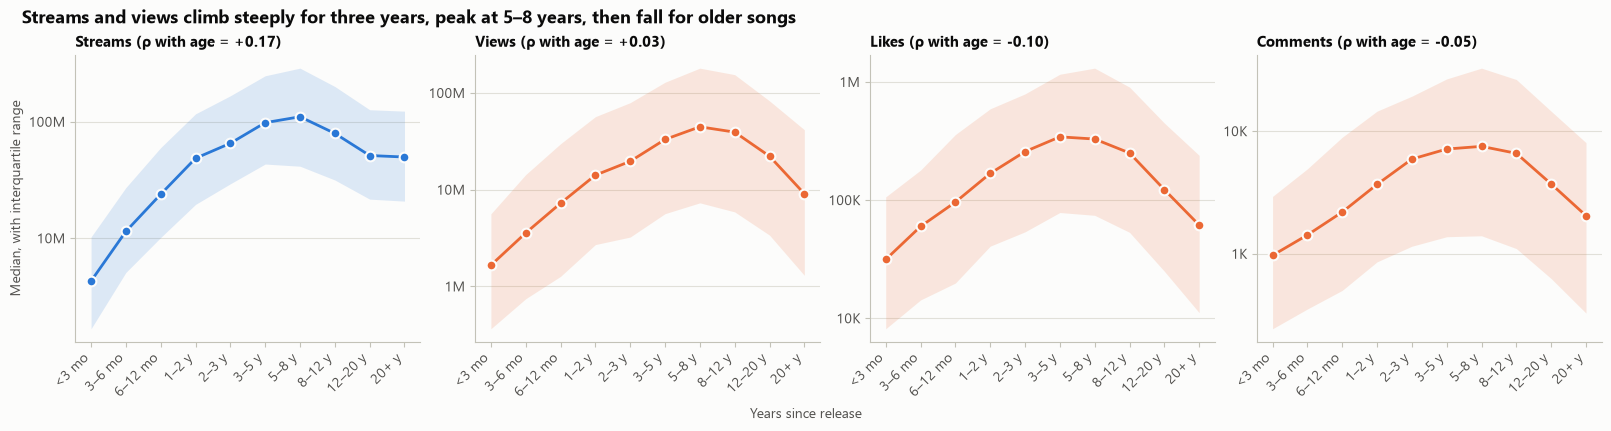

age_band,<3 mo,3–6 mo,6–12 mo,1–2 y,2–3 y,3–5 y,5–8 y,8–12 y,12–20 y,20+ y
Streams,4.3M,11.5M,23.9M,48.6M,65.4M,98.2M,110.4M,79.5M,51.3M,49.8M
Views,1.7M,3.6M,7.2M,14.1M,19.6M,33.1M,44.7M,39.4M,22.2M,9.1M
Likes,31.4K,59.8K,96.1K,168.2K,257.3K,343K,328.6K,250.6K,122.7K,61.4K
Comments,970,1.4K,2.2K,3.7K,5.9K,7.1K,7.5K,6.6K,3.7K,2K
tracks,866,739,1254,1305,934,1797,1792,1537,2499,4950


In [10]:
METRICS = [("Streams", music_sp, "log_stream", SPOTIFY), ("Views", music_yt, "log_views", YOUTUBE),
           ("Likes", music_yt, "log_likes", YOUTUBE), ("Comments", music_yt, "log_comments", YOUTUBE)]
x = np.arange(len(AGE_LABELS))

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), layout="constrained")
age_rho = {}
for ax, (name, data, col, colour) in zip(axes, METRICS):
    t = by_age(data, col)
    band_line(ax, x, t["median"], t.q1, t.q3, colour)
    age_rho[name] = stats.spearmanr(data[col], data.years_since_release, nan_policy="omit").statistic
    ax.set_title(f"{name} (ρ with age = {age_rho[name]:+.2f})")
    log_axis(ax.yaxis)
    age_ticks(ax)
axes[0].set_ylabel("Median, with interquartile range")
fig.supxlabel("Years since release", color=NEUTRAL, fontsize=10)
fig_title(fig, "Streams and views climb steeply for three years, peak at 5–8 years, then fall for older songs")
plt.show()

pd.DataFrame({name: by_age(data, col)["median"].map(lambda v: human(10 ** v)) for name, data, col, _ in METRICS}
             ).assign(tracks=by_age(music_sp, "log_stream").n).T

**Observations**

- **Time alone makes a 25× difference.** The median song under 3 months old has 4.3M streams. At 6–12 months it has 24M, and at 5–8 years 110M. Views follow the same curve: 1.7M → 7.2M → 45M.
- **After about 8 years the medians fall again** (50M streams and 9M views for songs over 20 years old). Old songs have not had *less* time, but:
  - most of their life predates Spotify (2008) and YouTube (2005), so their plays only count from then;
  - streaming audiences lean young;
  - fewer of them have an official video (65%, against 83–88% of newer songs, §5.2).
- **The low correlations hide this.** Because the curve rises and then falls, ρ with age is only +0.17 for streams and +0.03 for views. A correlation alone would wrongly suggest that age barely matters.
- Likes and comments rise and fall the same way, but their ρ with age is slightly negative (−0.10 and −0.05), because new videos collect more likes per view (§3.5).

### 3.2 The raw popularity tiers are really age tiers for new songs

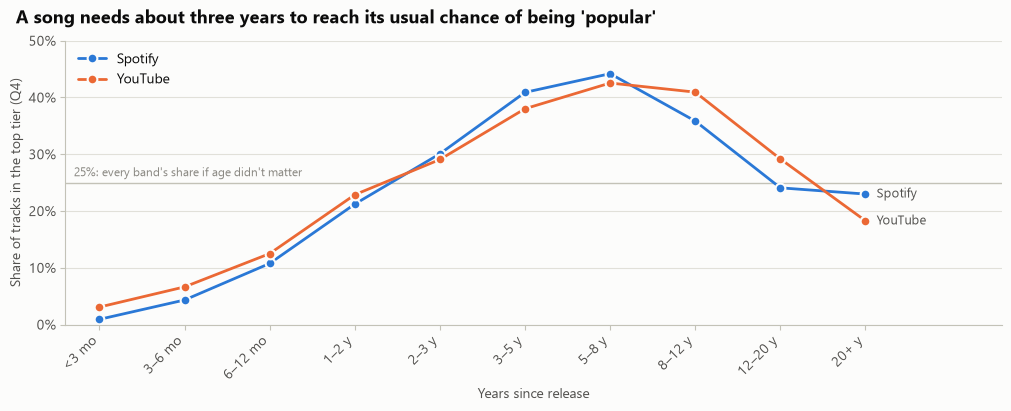

age_band,<3 mo,3–6 mo,6–12 mo,1–2 y,2–3 y,3–5 y,5–8 y,8–12 y,12–20 y,20+ y
Spotify,0.00924,0.0433,0.108,0.212,0.301,0.409,0.442,0.358,0.241,0.23
YouTube,0.0308,0.0664,0.125,0.229,0.291,0.38,0.425,0.409,0.292,0.183


In [11]:
top_share = pd.DataFrame({
    "Spotify": music_sp.spotify_tier.eq(TOP_TIER).groupby(music_sp.age_band, observed=False).mean(),
    "YouTube": music_yt.youtube_tier.eq(TOP_TIER).groupby(music_yt.age_band, observed=False).mean(),
})

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.axhline(0.25, color=FAINT, linewidth=1)
ax.text(-0.3, 0.256, "25%: every band's share if age didn't matter", va="bottom", ha="left", fontsize=8.5, color=MUTED)
for platform, colour in PLATFORM_COLOURS.items():
    ax.plot(x, top_share[platform], color=colour, marker="o", markeredgecolor=SURFACE, markeredgewidth=1.5, label=platform)
    ax.annotate(platform, (x[-1], top_share[platform].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=NEUTRAL)
ax.set_ylabel("Share of tracks in the top tier (Q4)")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.5)
ax.set_xlim(-0.4, len(x) + 0.6)
age_ticks(ax)
ax.set_xlabel("Years since release")
ax.legend(loc="upper left")
fig_title(fig, "A song needs about three years to reach its usual chance of being 'popular'")
plt.show()
top_share.T

**Observations**

- **Only 1% of songs under 3 months old are in Spotify's top tier (3% on YouTube), against 38–44% of songs aged 3–8 years.** If age didn't matter, every band would hold 25%.
- A song only reaches its usual chance of being "popular" at 2–3 years. For anything newer, v2's top-tier label mostly measures **how long the song has been out**. A new release that is a hit for its age is usually labelled Q1–Q3.
- Spotify and YouTube follow almost the same curve, so age biases both platforms' targets in the same way.

### 3.3 Within an artist's own songs, the older ones are bigger

v2 §7.4 compared songs *within* each artist to separate song-level from artist-level effects. That comparison assumes an artist's ten songs had similar time to accumulate plays. Here each artist's songs are split into fifths by age, from the artist's newest to oldest, and popularity is shown relative to the artist's own average.

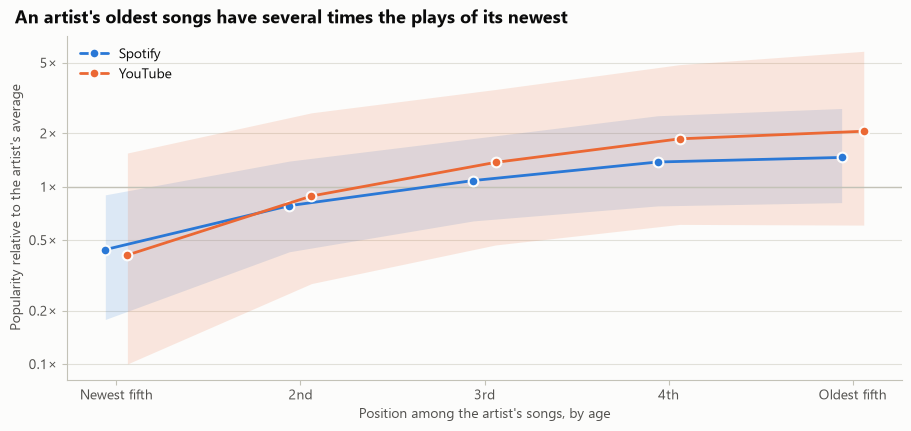

years_since_release,Newest fifth,2nd,3rd,4th,Oldest fifth
median vs artist average,,,,,
Spotify,0.44×,0.78×,1.08×,1.38×,1.46×
YouTube,0.41×,0.89×,1.37×,1.86×,2.06×


,all dated music,confirmed dates only
within-artist ρ of age with,,
Spotify (streams),0.31,0.32
YouTube (views),0.2,0.21


In [12]:
def artist_relative(data, col):
    """Popularity relative to the artist's mean (log10), for artists with 5+ dated songs."""
    data = data[data.groupby("Artist").Artist.transform("size") >= 5]
    age_pos = data.groupby("Artist").years_since_release.rank(pct=True)
    fifth = pd.cut(age_pos, [0, 0.2, 0.4, 0.6, 0.8, 1], labels=["Newest fifth", "2nd", "3rd", "4th", "Oldest fifth"])
    rel = data[col] - data.groupby("Artist")[col].transform("mean")
    return rel.groupby(fifth, observed=False).agg(["median", lambda s: s.quantile(0.25), lambda s: s.quantile(0.75)])


def within_artist_rho(data, a, b):
    data = data[data.groupby("Artist").Artist.transform("size") >= 2]
    da = data[a] - data.groupby("Artist")[a].transform("mean")
    db = data[b] - data.groupby("Artist")[b].transform("mean")
    return stats.spearmanr(da, db, nan_policy="omit").statistic


fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
ax.axhline(0, color=FAINT, linewidth=1)
xs = np.arange(5)
fifths = {}
for (platform, colour), (data, col) in zip(PLATFORM_COLOURS.items(), [(music_sp, "log_stream"), (music_yt, "log_views")]):
    t = artist_relative(data, col)
    fifths[platform] = (10 ** t.iloc[:, 0]).map(lambda v: f"{v:.2f}×")
    band_line(ax, xs + (-0.06 if platform == "Spotify" else 0.06), t.iloc[:, 0], t.iloc[:, 1], t.iloc[:, 2], colour, platform)
ax.set_xticks(xs, t.index)
ax.grid(axis="x", visible=False)
times_axis(ax.yaxis)
ax.set_ylabel("Popularity relative to the artist's average")
ax.set_xlabel("Position among the artist's songs, by age")
ax.legend(loc="upper left")
fig_title(fig, "An artist's oldest songs have several times the plays of its newest")
plt.show()
display(pd.DataFrame(fifths).T.rename_axis("median vs artist average"))

pd.DataFrame({
    "all dated music": {"Spotify (streams)": within_artist_rho(music_sp, "years_since_release", "log_stream"),
                        "YouTube (views)": within_artist_rho(music_yt, "years_since_release", "log_views")},
    "confirmed dates only": {
        "Spotify (streams)": within_artist_rho(reliable[reliable.Stream.notna()], "years_since_release", "log_stream"),
        "YouTube (views)": within_artist_rho(reliable[reliable.yt_primary], "years_since_release", "log_views")},
}).rename_axis("within-artist ρ of age with").round(2)

**Observations**

- **Within an artist's own top 10, age is a major driver of popularity.** The artist's newest fifth of songs has a median of 0.44× the artist's average streams, and the oldest fifth 1.46×, a gap of about 3.3×. On YouTube the gap is about 5× (0.41× vs 2.06×).
- The within-artist ρ of age is **+0.31 with streams and +0.20 with views**, and almost the same on confirmed dates only (+0.32 and +0.21). No audio feature comes close: the largest within-artist feature ρ in v2 was about 0.16 (Duration).
- **This confounds v2 §7.4.** Within-artist comparisons assumed an artist's songs had comparable time to collect plays, and they didn't. §5.4 repeats that analysis with age controlled.

### 3.4 Age is also linked to the audio features

Music has changed over the decades (songs have become shorter, louder and more rap-influenced). If newer songs sound different *and* have had less time to collect plays, a pooled correlation between a feature and popularity mixes the two.

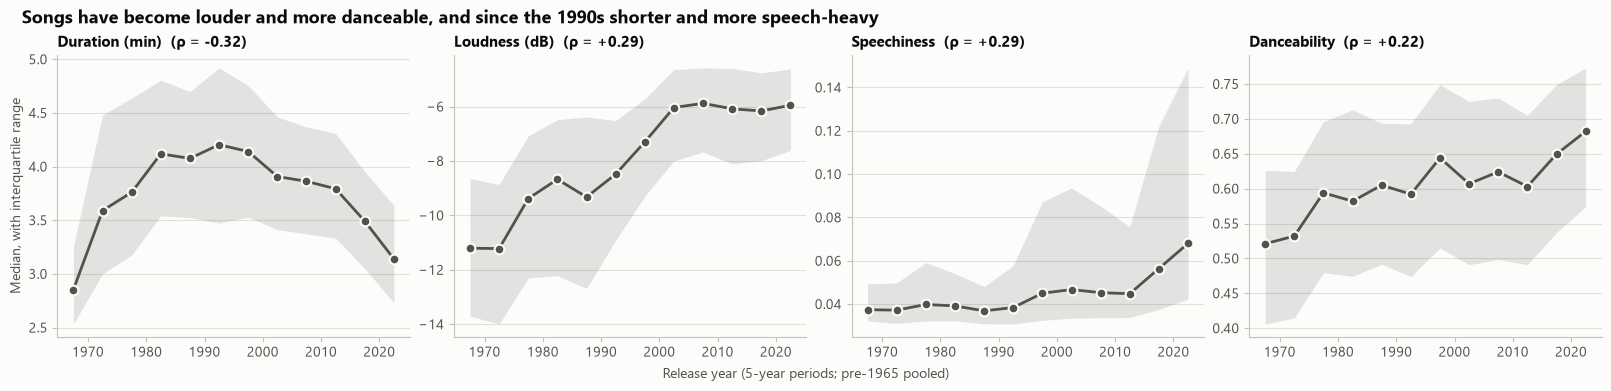

,Duration (min),Loudness (dB),Speechiness,Danceability,Instrumentalness,Valence,Energy,Tempo (BPM),Acousticness,Liveness
ρ with release year,-0.316,0.294,0.292,0.215,-0.176,-0.102,0.087,0.048,-0.04,0.025


In [13]:
era_rho = pd.Series({f: stats.spearmanr(music[f], music.release_year.astype(float)).statistic for f in AUDIO_FEATURES})
era_rho = era_rho.reindex(era_rho.abs().sort_values(ascending=False).index)
TREND_FEATURES = era_rho.index[:4]
period = (music.release_year.astype(float).clip(lower=1965) // 5 * 5).rename("period")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), layout="constrained")
for ax, f in zip(axes, TREND_FEATURES):
    values = music.duration_min if f == "Duration_ms" else music[f]
    g = values.groupby(period)
    band_line(ax, g.median().index + 2.5, g.median(), g.quantile(0.25), g.quantile(0.75), NEUTRAL)
    ax.set_title(f"{FEATURE_LABELS.get(f, f)}  (ρ = {era_rho[f]:+.2f})")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(10))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Median, with interquartile range")
fig.supxlabel("Release year (5-year periods; pre-1965 pooled)", color=NEUTRAL, fontsize=10)
fig_title(fig, "Songs have become louder and more danceable, and since the 1990s shorter and more speech-heavy")
plt.show()

era_rho.rename(index=FEATURE_LABELS).rename("ρ with release year").to_frame().round(3).T

**Observations**

- **Age is linked to the audio features as well as to popularity, so it meets the definition of a confounder.** The strongest links with release year:
  - **Duration** (ρ −0.32): the median grew from under 3 minutes in the 1960s to about 4.2 minutes in the 1990s, then fell to about 3.1 minutes for 2020s songs.
  - **Loudness** (+0.29): from about −11 dB in the late 1960s to −6 dB from the 2000s on, the "loudness war".
  - **Speechiness** (+0.29): flat at about 0.04 until the mid-2010s, then up to 0.068 in the 2020s, with the rise of rap and reggaeton.
  - **Danceability** (+0.22): from about 0.52 to 0.68.
  - **Instrumentalness** falls (−0.18).
- **What this predicts:** in raw counts, the features of *new* songs (short, speechy, danceable, loud) should look less popular than they are, because those songs have had less time. The features of *older* songs (long) should look more popular. §5.3 tests this.

### 3.5 Engagement rates depend on age too

v2 suggested like-rate (likes per view) as an engagement measure that is independent of reach. It is not independent of age.

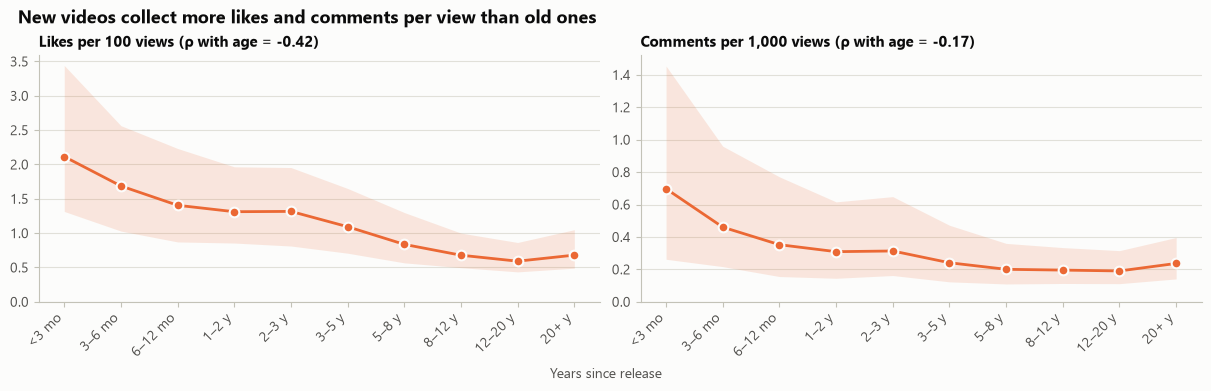

age_band,<3 mo,3–6 mo,6–12 mo,1–2 y,2–3 y,3–5 y,5–8 y,8–12 y,12–20 y,20+ y
likes per 100 views,2.11,1.69,1.41,1.31,1.32,1.09,0.84,0.68,0.59,0.68
"comments per 1,000 views",0.7,0.46,0.35,0.31,0.31,0.24,0.2,0.2,0.19,0.24


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, (col, scale, label) in zip(axes, [("like_rate", 100, "Likes per 100 views"), ("comment_rate", 1000, "Comments per 1,000 views")]):
    t = by_age(music_yt, col) * [scale, scale, scale, 1]
    band_line(ax, x, t["median"], t.q1, t.q3, YOUTUBE)
    rho_rate = stats.spearmanr(music_yt[col], music_yt.years_since_release, nan_policy="omit").statistic
    ax.set_title(f"{label} (ρ with age = {rho_rate:+.2f})")
    ax.set_ylim(bottom=0)
    age_ticks(ax)
fig.supxlabel("Years since release", color=NEUTRAL, fontsize=10)
fig_title(fig, "New videos collect more likes and comments per view than old ones")
plt.show()
pd.DataFrame({"likes per 100 views": by_age(music_yt, "like_rate")["median"] * 100,
              "comments per 1,000 views": by_age(music_yt, "comment_rate")["median"] * 1000}).T.round(2)

**Observations**

- **The median like rate falls from 2.1 likes per 100 views for videos under 3 months old to about 0.6–0.7 for videos over 8 years.** Comments fall from 0.70 to about 0.2 per 1,000 views. ρ with age is −0.42 for likes and −0.17 for comments. The like-rate link is stronger than any audio feature's link with popularity.
- Two likely reasons:
  - Early viewers are fans who like and comment. Later views come from search, recommendations and background play.
  - Liking habits have changed over the years.
- **v2's `like_rate` is therefore not an age-free engagement measure.** Compare like rates only between songs of similar age, using `age_band` as a filter, or `likes_vs_age` minus `views_vs_age`.

## 4. Aggregating popularity over time

Two ways to put songs of different ages on an equal footing are compared:

1. **Per-year rates** (`streams_per_year`, `views_per_year`, `likes_per_year`, `comments_per_year`): the count divided by the years the song has been available on the platform. The exposure time starts at the release date, or at the platform's launch for older songs (Spotify: Oct 2008; YouTube: Dec 2005), because no song could collect plays before the platform existed. It is floored at one month. YouTube has no upload dates in this file, so its exposure uses the release date as a stand-in. These rates are computed here only for the comparison; they are not in the CSV.
2. **Age-relative scores** (`stream_vs_age`, `views_vs_age`, `likes_vs_age`, `comments_vs_age`, already in the CSV): the log count minus the median log count of songs in the **same age band**. A score of +1 means 10× more than a typical song of the same age, and 0 means typical for its age. The same idea gives age-adjusted tiers (`spotify_tier_age_adj`, `youtube_tier_age_adj`): popularity quartiles computed within each age band.

A rate assumes plays arrive at a steady pace. An age-relative score makes no assumption about the shape of the curve.

In [15]:
def exposure_years(launch):
    start = df.release_date.mask(df.release_date < launch, launch)       # NaT stays NaT
    return ((COLLECTION_DATE - start).dt.days / 365.25).clip(lower=1 / 12)


df["spotify_exposure_years"] = exposure_years(SPOTIFY_LAUNCH)
df["youtube_exposure_years"] = exposure_years(YOUTUBE_LAUNCH)
df["streams_per_year"] = df.Stream / df.spotify_exposure_years
for col in ["Views", "Likes", "Comments"]:
    df[f"{col.lower()}_per_year"] = df[col] / df.youtube_exposure_years

# Refresh the analysis frames with the new columns
dated = df[has_date]
music = dated[~dated.is_spoken_word]
music_sp, music_yt = music[music.Stream.notna()], music[music.yt_primary]
reliable = music[music.release_date_confidence.eq("confirmed")]

df.loc[has_date, ["Artist", "Track", "years_since_release", "Stream", "streams_per_year", "stream_vs_age",
                  "spotify_tier", "spotify_tier_age_adj"]].sample(6, random_state=11)

,Artist,Track,years_since_release,Stream,streams_per_year,stream_vs_age,spotify_tier,spotify_tier_age_adj
6385,Salim–Sulaiman,Chak De India,15.52,"9,329,698","650,816",-0.74,Q1 (Low),Q1 (Low)
11859,Neeraj Shridhar,Bhool Bhulaiyaa,15.61,"16,047,296","1,119,418",-0.505,Q1 (Low),Q1 (Low)
17026,MC Cabelinho,QUEM SOU EU?,0.13,"6,886,271","51,330,826",0.255,Q1 (Low),Q3
9720,Shafqat Amanat Ali,Teri Jhuki Nazar - Lofi Flip,10.02,"948,088","94,666",-1.92,Q1 (Low),Q1 (Low)
10427,Phil Wickham,Living Hope,4.86,"77,781,470","16,005,455",-0.101,Q3,Q2
5615,Elliott Smith,Pitseleh,24.61,"15,010,821","1,047,117",-0.519,Q1 (Low),Q1 (Low)


### 4.1 Which aggregation removes the age effect?

Each line shows the median song in an age band relative to the median of all songs. A measure that is free of age would be flat at 1×.

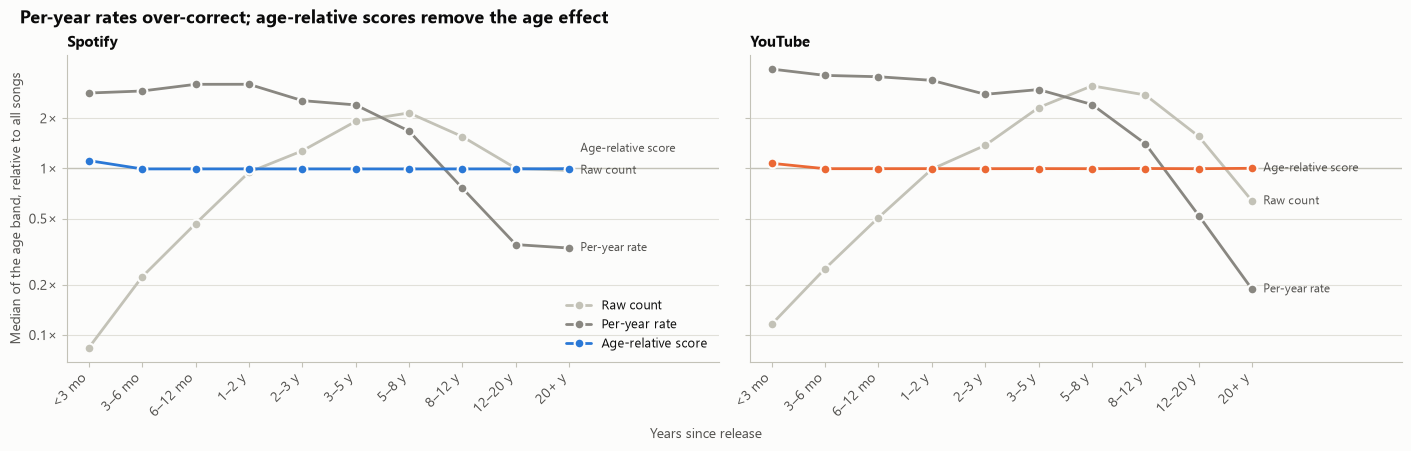

ρ with age  within-artist ρ with age  newest band vs all (×)  oldest band vs all (×)
Spotify Raw count                 0.17                      0.31                    0.08                    0.97
        Per-year rate            -0.56                     -0.21                    2.83                    0.33
        Age-relative score       -0.00                       0.2                    1.11                    1.00
YouTube Raw count                 0.03                       0.2                    0.12                    0.64
        Per-year rate            -0.46                      -0.1                    3.95                    0.19
        Age-relative score       -0.02                      0.14                    1.07                    1.00

In [16]:
VARIANTS = {"Raw count": ("log_stream", "log_views"),
            "Per-year rate": ("streams_per_year", "views_per_year"),
            "Age-relative score": ("stream_vs_age", "views_vs_age")}


def as_log(data, col):
    return np.log10(data[col].where(data[col] > 0)) if col.endswith("per_year") else data[col]


fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), layout="constrained", sharey=True)
summary = {}
for ax, (platform, colour), data, k in zip(axes, PLATFORM_COLOURS.items(), [music_sp, music_yt], [0, 1]):
    ax.axhline(0, color=FAINT, linewidth=1)
    ends = {}
    for (variant, cols), line_colour in zip(VARIANTS.items(), [FAINT, MUTED, colour]):
        values = as_log(data, cols[k])
        med = values.groupby(data.age_band, observed=False).median() - values.median()
        ax.plot(x, med, color=line_colour, marker="o", markeredgecolor=SURFACE, markeredgewidth=1.5, label=variant)
        ends[variant] = med.iloc[-1]
        summary[(platform, variant)] = {
            "ρ with age": stats.spearmanr(values, data.years_since_release, nan_policy="omit").statistic,
            "within-artist ρ with age": within_artist_rho(data.assign(v=values), "years_since_release", "v"),
            "newest band vs all (×)": 10 ** med.iloc[0], "oldest band vs all (×)": 10 ** med.iloc[-1]}
    label_y = sorted(ends.items(), key=lambda kv: kv[1])
    for i in range(1, len(label_y)):                     # keep end labels at least 0.13 apart
        label_y[i] = (label_y[i][0], max(label_y[i][1], label_y[i - 1][1] + 0.13))
    for variant, y in label_y:
        ax.annotate(variant, (x[-1], y), xytext=(8, 0), textcoords="offset points", va="center", fontsize=8.5, color=NEUTRAL)
    ax.set_title(platform)
    ax.set_xlim(-0.4, len(x) + 1.8)
    age_ticks(ax)
    times_axis(ax.yaxis)
axes[0].set_ylabel("Median of the age band, relative to all songs")
axes[0].legend(loc="lower right", fontsize=9)
fig.supxlabel("Years since release", color=NEUTRAL, fontsize=10)
fig_title(fig, "Per-year rates over-correct; age-relative scores remove the age effect")
plt.show()
pd.DataFrame(summary).T.round(2)

**Observations**

- **Raw counts:** the newest band sits at 0.08× the typical song on Spotify and 0.12× on YouTube.
- **Per-year rates over-correct and reverse the bias.**
  - The newest songs jump to 2.8× typical (Spotify) and 4.0× (YouTube), and songs over 20 years old fall to 0.33× and 0.19×.
  - ρ with age turns strongly negative (−0.56 and −0.46).
  - The cause: a rate assumes plays arrive at a steady pace, but most arrive in a song's first years (§3.1). Old songs also only start counting at the platform's launch.
- **Age-relative scores remove the age effect across songs.** Every band sits at about 1× (ρ with age −0.00 and −0.02).
- **Within an artist, some of the age effect remains** (ρ +0.20 and +0.14). An artist's own songs differ more by age than the dataset-wide bands capture. For within-artist questions, control for each song's age directly, as §5.4 does.
- **Recommendation:**
  - Use `stream_vs_age` / `views_vs_age` and the age-adjusted tiers as the time-fair popularity measures.
  - Keep per-year rates as an intuitive "plays per year" figure, meaningful only for songs past the first few years.

## 5. Which v2 findings change once age is controlled?

### 5.1 Who is "popular"?

In [17]:
moved = pd.crosstab(music_sp.spotify_tier, music_sp.spotify_tier_age_adj, normalize="index")
print(f"Spotify tracks whose tier changes after adjusting for age: {(music_sp.spotify_tier.astype(str) != music_sp.spotify_tier_age_adj.astype(str)).mean():.0%}")
display(moved.rename_axis(index="raw tier", columns="age-adjusted tier").round(2))

show = ["Artist", "Track", "release_date", "Stream", "spotify_tier", "spotify_tier_age_adj"]
print("Under a year old and top-tier for their age, but not top-tier overall:")
new_hits = music_sp[(music_sp.years_since_release < 1) & music_sp.spotify_tier_age_adj.eq(TOP_TIER) & music_sp.spotify_tier.ne(TOP_TIER)]
display(new_hits.nlargest(8, "stream_vs_age")[show].assign(Stream=lambda d: human_col(d.Stream)))
print(f"({len(new_hits):,} such tracks)")

Spotify tracks whose tier changes after adjusting for age: 29%


age-adjusted tier,Q1 (Low),Q2,Q3,Q4 (Top)
raw tier,,,,
Q1 (Low),0.76,0.14,0.08,0.03
Q2,0.27,0.61,0.08,0.04
Q3,0.00,0.25,0.65,0.1
Q4 (Top),0.00,0.00,0.19,0.81


Under a year old and top-tier for their age, but not top-tier overall:


,Artist,Track,release_date,Stream,spotify_tier,spotify_tier_age_adj
16933,Central Cee,LET GO,2022-12-15,126.7M,Q3,Q4 (Top)
15726,SZA,Nobody Gets Me,2022-12-08,123M,Q3,Q4 (Top)
17545,Ovy On The Drums,CAIRO,2022-11-13,109.6M,Q3,Q4 (Top)
16360,Bad Bunny,Gato de Noche,2022-12-22,96.1M,Q3,Q4 (Top)
13125,back number,水平線,2023-01-17,95.1M,Q3,Q4 (Top)
15727,SZA,Low,2022-12-09,94.2M,Q3,Q4 (Top)
15354,LUDMILLA,Teu Segredo - Ao Vivo,2022-12-16,83.9M,Q3,Q4 (Top)
17396,Bizarrap,"Duki: Bzrp Music Sessions, Vol. 50",2022-11-16,81.9M,Q3,Q4 (Top)


(556 such tracks)


**Observations**

- **29% of Spotify tracks change tier once age is taken into account.**
  - 81% of the raw top tier stays top tier. The other 19% drop to Q3: mostly older songs whose large counts are only typical for their age.
  - In the other direction, 556 tracks under a year old are top-tier *for their age* but not overall. Examples: Central Cee's *LET GO* and SZA's *Nobody Gets Me*, both released in December 2022 and past 120M streams within two months.
- The list also shows a remaining date problem: back number's *水平線* is here because its date is 2023, although it came out in 2020 (§2.4).

### 5.2 Platform agreement and lean

In [18]:
paired = music_sp[music_sp.yt_primary]
display(pd.Series({
    "ρ streams vs views (raw)": stats.spearmanr(paired.log_stream, paired.log_views).statistic,
    "ρ streams vs views (age-relative)": stats.spearmanr(paired.stream_vs_age, paired.views_vs_age).statistic,
    "ρ lean_score with age": stats.spearmanr(paired.lean_score, paired.years_since_release, nan_policy="omit").statistic,
}).round(3).to_frame("value"))
lean_by_age = pd.DataFrame({
    "tracks": paired.groupby("age_band", observed=False).size(),
    "median lean_score": paired.groupby("age_band", observed=False).lean_score.median(),
    "Spotify-leaning": paired.platform_lean.eq("Spotify-leaning").groupby(paired.age_band, observed=False).mean(),
    "YouTube-leaning": paired.platform_lean.eq("YouTube-leaning").groupby(paired.age_band, observed=False).mean(),
    "official video": paired.official_video.eq(True).groupby(paired.age_band, observed=False).mean(),
})
lean_by_age.round(2)

,value
ρ streams vs views (raw),0.62
ρ streams vs views (age-relative),0.585
ρ lean_score with age,-0.1


,tracks,median lean_score,Spotify-leaning,YouTube-leaning,official video
age_band,,,,,
<3 mo,828,0.26,0.1,0.21,0.83
3–6 mo,721,0.18,0.13,0.18,0.86
6–12 mo,1200,0.12,0.15,0.16,0.88
1–2 y,1252,0.14,0.16,0.17,0.85
2–3 y,890,0.1,0.19,0.2,0.86
3–5 y,1733,0.2,0.17,0.21,0.84
5–8 y,1731,0.29,0.18,0.26,0.83
8–12 y,1475,0.36,0.17,0.29,0.8
12–20 y,2389,0.34,0.18,0.24,0.77


**Observations**

- **Platform agreement barely changes:** ρ between streams and views is 0.62 on raw counts and 0.59 on age-relative scores. Age adds a little shared variation (both counts grow with time), but it isn't the source of the agreement.
- **v2's `lean_score` is nearly free of age** (ρ −0.10). Both platforms follow the same age curve, so a views-to-streams ratio cancels most of it. Only the extremes differ:
  - **Songs under 3 months lean YouTube:** median lean +0.26, with 21% YouTube-leaning and only 10% Spotify-leaning. Music videos peak around release.
  - **Songs aged 8–20 years lean YouTube most** (median +0.34 to +0.36). They were released in 2003–2015, as YouTube music videos took off.
  - **Songs over 20 years old are balanced:** median lean 0.01, with 27% Spotify-leaning and 14% YouTube-leaning. Only 65% have an official video, against 83–88% of songs under 8 years.
- `platform_lean` can stay as it is in the dashboard. Read its extremes alongside age.

### 5.3 Audio features vs popularity, across all songs

v2 §7.1 correlated each feature with log streams and log views. Here the same correlation is computed with the age-relative score, which compares each song only with songs of the same age.

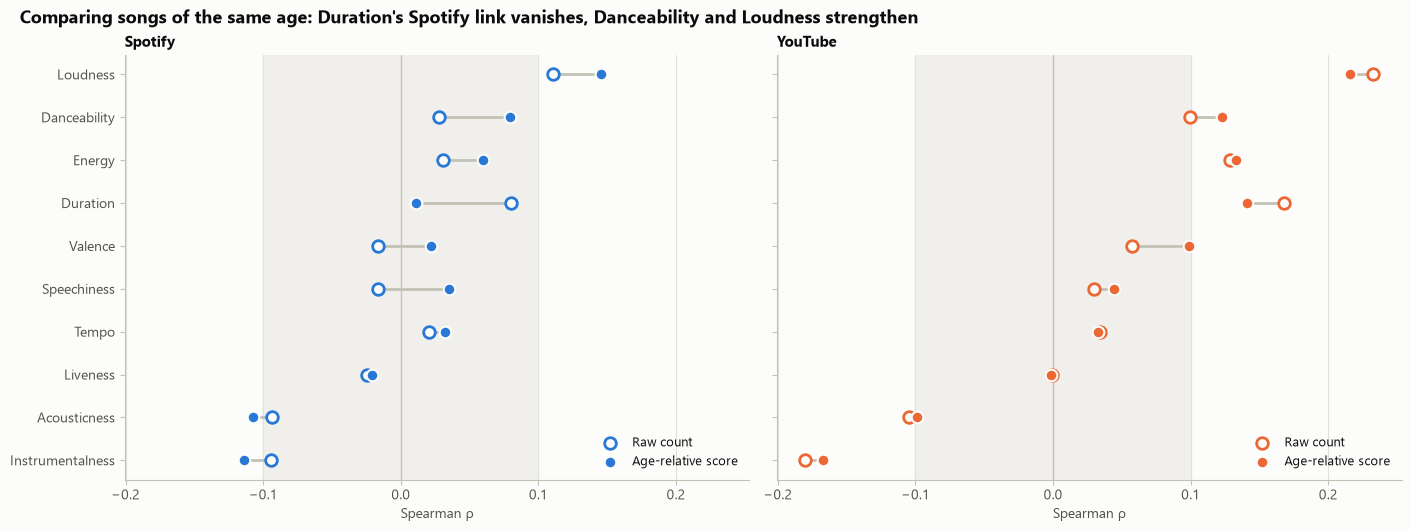

Spotify                                            YouTube                                           
                     raw age-relative age-relative, confirmed dates     raw age-relative age-relative, confirmed dates
Instrumentalness  -0.094       -0.114                        -0.108   -0.18       -0.167                        -0.156
Acousticness      -0.094       -0.108                        -0.084  -0.105       -0.099                        -0.094
Liveness          -0.024       -0.021                        -0.025   -0.00       -0.002                        -0.011
Tempo (BPM)        0.021        0.032                         0.026   0.034        0.032                         0.026
Speechiness       -0.016        0.035                         0.035    0.03        0.045                         0.036
Valence           -0.017        0.022                          0.03   0.057        0.099                         0.095
Duration (min)      0.08        0.011                         0.017   0.168        0.141                         0.153
Energy             0.031         0.06                         0.052   0.129        0.133                         0.127
Danceability       0.028        0.079                         0.079   0.099        0.123                         0.116
Loudness (dB)      0.111        0.146                         0.134   0.233        0.216                         0.201

In [19]:
def rho_table(data, target):
    return pd.Series({f: stats.spearmanr(data[f], data[target], nan_policy="omit").statistic for f in AUDIO_FEATURES})


pooled = pd.DataFrame({
    ("Spotify", "raw"): rho_table(music_sp, "log_stream"), ("Spotify", "age-relative"): rho_table(music_sp, "stream_vs_age"),
    ("YouTube", "raw"): rho_table(music_yt, "log_views"), ("YouTube", "age-relative"): rho_table(music_yt, "views_vs_age"),
})
order = pooled.xs("age-relative", axis=1, level=1).mean(axis=1).sort_values().index
pooled = pooled.loc[order]
labels = [FEATURE_LABELS.get(f, f).split(" (")[0] for f in order]
ypos = np.arange(len(order))


def dumbbell(table, title, before="raw", after="age-relative", before_label="Raw count", after_label="Age-relative score"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), layout="constrained", sharex=True, sharey=True)
    for ax, (platform, colour) in zip(axes, PLATFORM_COLOURS.items()):
        b, a = table[(platform, before)], table[(platform, after)]
        ax.axvspan(-0.1, 0.1, color=MIDPOINT, zorder=0)
        ax.axvline(0, color=FAINT, linewidth=1)
        ax.hlines(ypos, np.minimum(b, a), np.maximum(b, a), color=FAINT, linewidth=2, zorder=1)
        ax.scatter(b, ypos, s=70, facecolor=SURFACE, edgecolor=colour, linewidth=2, zorder=3, label=before_label)
        ax.scatter(a, ypos, s=70, color=colour, edgecolor=SURFACE, linewidth=1.5, zorder=3, label=after_label)
        ax.set_title(platform)
        ax.set_xlabel("Spearman ρ")
        ax.grid(axis="y", visible=False)
        ax.legend(loc="lower right", fontsize=9)
    axes[0].set_yticks(ypos, labels)
    fig_title(fig, title)
    plt.show()


dumbbell(pooled, "Comparing songs of the same age: Duration's Spotify link vanishes, Danceability and Loudness strengthen")
pooled_reliable = pd.DataFrame({
    ("Spotify", "age-relative, confirmed dates"): rho_table(reliable[reliable.Stream.notna()], "stream_vs_age"),
    ("YouTube", "age-relative, confirmed dates"): rho_table(reliable[reliable.yt_primary], "views_vs_age")})
pd.concat([pooled, pooled_reliable], axis=1).sort_index(axis=1, level=0, sort_remaining=False).rename(index=FEATURE_LABELS).round(3)

**Observations**

- **Comparing songs of the same age shifts several v2 associations, all in the direction §3.4 predicted:**
  - **Duration on Spotify was an age artefact.** ρ falls from 0.080 to 0.011 (0.018 on confirmed dates): longer songs are older, and older songs have more streams. On YouTube it shrinks from 0.17 to 0.14 but survives.
  - **Features of modern songs were understated.** On Spotify:
    - Danceability: 0.028 → 0.079;
    - Loudness: 0.111 → 0.146;
    - Speechiness: −0.016 → 0.035;
    - Valence: −0.017 → 0.022.
  - On YouTube, Danceability (0.099 → 0.123) and Valence (0.057 → 0.099) strengthen.
  - Liveness, Tempo and Acousticness barely move.
- **Every association is still weak (|ρ| ≤ 0.23)**, so v2's headline stands: no audio feature strongly orders tracks by popularity. **The ranking changes, though:**
  - On Spotify, Loudness now leads, followed by Danceability. Instrumentalness and Acousticness lead negatively, and Duration drops out.
  - On YouTube, Loudness leads, with Duration, Energy and Danceability behind (0.12–0.14).
- Confirmed dates alone give the same picture (within 0.03), so these shifts are not caused by the remaining date errors.

### 5.4 Audio features vs popularity, within each artist

v2 §7.4 found that most feature links vanish within an artist's own songs, with **Duration** the one exception. Within an artist, age has an even stronger effect (§3.3), so the age-relative score (which uses dataset-wide age bands) is not enough here. Instead, both the feature and the popularity are ranked within each artist, and the song's age rank is regressed out of both before correlating them (a within-artist partial correlation).

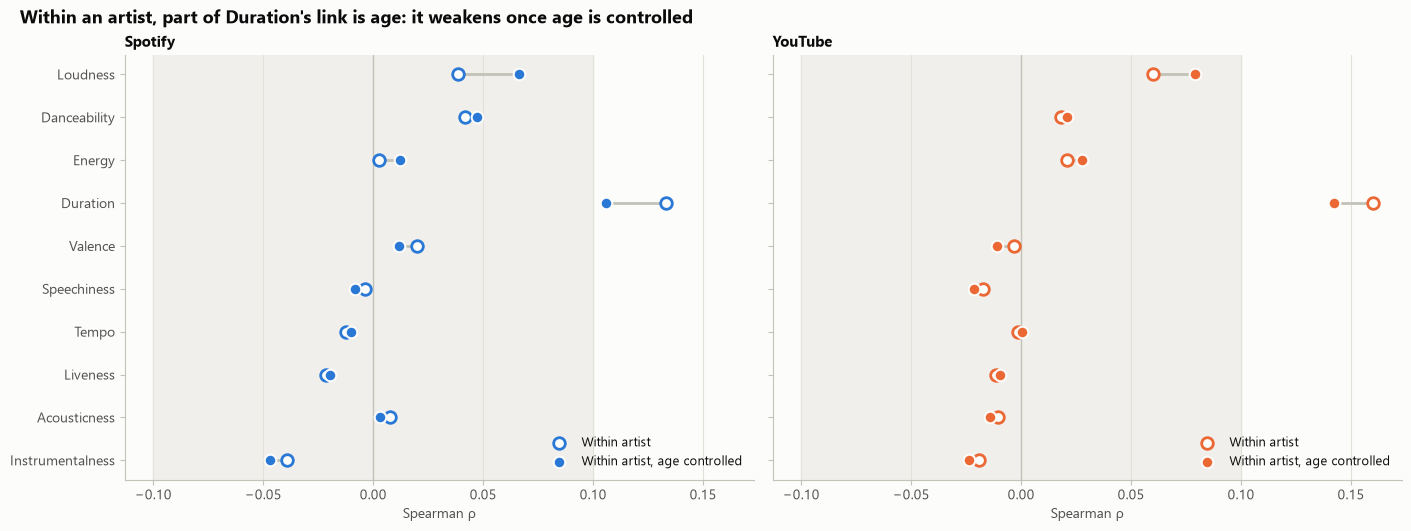

Spotify                                                                     YouTube                                      \
                     raw age-controlled raw, confirmed dates age-controlled, confirmed dates     raw age-controlled raw, confirmed dates   
Instrumentalness  -0.039         -0.047               -0.044                          -0.053  -0.019         -0.024               -0.025   
Acousticness       0.008          0.003                0.004                           0.003  -0.011         -0.014               -0.012   
Liveness          -0.021          -0.02               -0.027                          -0.026  -0.011          -0.01               -0.017   
Tempo (BPM)       -0.012          -0.01               -0.011                          -0.008  -0.002           0.00               -0.001   
Speechiness       -0.004         -0.008               -0.001                          -0.007  -0.017         -0.021               -0.019   
Valence             0.02          0.012                0.019                           0.015  -0.003         -0.011               -0.004   
Duration (min)     0.133          0.106                0.134                           0.106    0.16          0.142                0.163   
Energy             0.002          0.012                0.006                           0.015   0.021          0.028                0.021   
Danceability       0.042          0.047                0.038                           0.046   0.018          0.021                0.024   
Loudness (dB)      0.039          0.066                0.039                           0.066    0.06          0.079                0.059   

                                                  
                 age-controlled, confirmed dates  
Instrumentalness                          -0.031  
Acousticness                              -0.013  
Liveness                                  -0.016  
Tempo (BPM)                                 0.00  
Speechiness                               -0.025  
Valence                                   -0.009  
Duration (min)                             0.145  
Energy                                     0.027  
Danceability                               0.029  
Loudness (dB)                              0.077

In [20]:
def within_rho(data, feature, target, control_age):
    cols = [feature, target, "years_since_release"]
    data = data.dropna(subset=cols)
    data = data[data.groupby("Artist").Artist.transform("size") >= 3]
    r = data.groupby("Artist")[cols].rank()
    r = r - r.groupby(data.Artist).transform("mean")
    if control_age:
        age = r["years_since_release"]
        for c in (feature, target):
            r[c] = r[c] - np.polyval(np.polyfit(age, r[c], 1), age)
    return np.corrcoef(r[feature], r[target])[0, 1]


within = {}
for platform, data, target in [("Spotify", music_sp, "log_stream"), ("YouTube", music_yt, "log_views")]:
    within[(platform, "raw")] = pd.Series({f: within_rho(data, f, target, False) for f in AUDIO_FEATURES})
    within[(platform, "age-controlled")] = pd.Series({f: within_rho(data, f, target, True) for f in AUDIO_FEATURES})
within = pd.DataFrame(within).loc[order]
dumbbell(within, "Within an artist, part of Duration's link is age: it weakens once age is controlled",
         after="age-controlled", before_label="Within artist", after_label="Within artist, age controlled")

rel_sp, rel_yt = reliable[reliable.Stream.notna()], reliable[reliable.yt_primary]
within_reliable = pd.DataFrame({
    ("Spotify", "raw, confirmed dates"): pd.Series({f: within_rho(rel_sp, f, "log_stream", False) for f in AUDIO_FEATURES}),
    ("Spotify", "age-controlled, confirmed dates"): pd.Series({f: within_rho(rel_sp, f, "log_stream", True) for f in AUDIO_FEATURES}),
    ("YouTube", "raw, confirmed dates"): pd.Series({f: within_rho(rel_yt, f, "log_views", False) for f in AUDIO_FEATURES}),
    ("YouTube", "age-controlled, confirmed dates"): pd.Series({f: within_rho(rel_yt, f, "log_views", True) for f in AUDIO_FEATURES}),
})
pd.concat([within, within_reliable], axis=1).sort_index(axis=1, level=0, sort_remaining=False).rename(index=FEATURE_LABELS).round(3)

**Observations**

- **v2's "one genuine track-level link" is mostly real, but part of it is age.** Within an artist, controlling for each song's age weakens Duration's link:
  - Spotify: 0.133 → 0.106, about a fifth weaker (0.134 → 0.106 on confirmed dates);
  - YouTube: 0.160 → 0.142 (0.163 → 0.145).

  An artist's older hits tend to be longer, and older songs have more plays.
- The remaining Duration link may come from short interludes and edits at the bottom of each artist's catalogue, or from longer videos with extended intros.
- The other features stay negligible within artists (|ρ| < 0.05), except Loudness, which rises slightly once age is controlled (Spotify 0.04 → 0.07; YouTube 0.06 → 0.08).
- The v2 conclusion holds: the pooled associations mostly describe **which kinds of artists and eras are big**, not what makes one song beat another by the same artist.

## 6. Does the new CSV address the feedback?

In [21]:
pd.Series({
    "Tracks with a release date": f"{has_date.sum():,} of {len(df):,} ({has_date.mean():.1%})",
    "Confidence: confirmed / single source / edition date only": " / ".join(
        f"{df.release_date_confidence.eq(c).sum():,}" for c in CONFIDENCE_ORDER),
    "Hand check, wrong year: first version → this file": " → ".join(f"{v:.0%}" for v in hand_check["wrong year"]),
    "Hand check, more than 1 year off: first version → this file": " → ".join(f"{v:.0%}" for v in hand_check["more than 1 year off"]),
    "Within-artist ρ of age with streams": f"{within_artist_rho(music_sp, 'years_since_release', 'log_stream'):+.2f}",
    "Top-tier share, songs < 3 months vs 3–5 years (Spotify)": f"{top_share.Spotify.iloc[0]:.0%} vs {top_share.Spotify.loc['3–5 y']:.0%}",
    "Spotify Duration ρ: raw → age-relative": f"{pooled.loc['Duration_ms', ('Spotify', 'raw')]:+.3f} → {pooled.loc['Duration_ms', ('Spotify', 'age-relative')]:+.3f}",
}).to_frame("value")

,value
Tracks with a release date,"18,256 of 18,847 (96.9%)"
Confidence: confirmed / single source / edition date only,"14,980 / 1,670 / 1,606"
"Hand check, wrong year: first version → this file",26% → 9%
"Hand check, more than 1 year off: first version → this file",17% → 2%
Within-artist ρ of age with streams,+0.31
"Top-tier share, songs < 3 months vs 3–5 years (Spotify)",1% vs 41%
Spotify Duration ρ: raw → age-relative,+0.080 → +0.011


### Does the new CSV address the feedback? Yes for streams, partly for YouTube

| Feedback point | Addressed? | Evidence | Still needed |
|---|---|---|---|
| Streams accumulate over time | **Yes**, for 97% of tracks | A song's age explains a 25× range in median streams (§3.1). Age-relative scores remove it (ρ with age −0.00, §4.1) | Nothing essential |
| Views, likes and comments accumulate over time | **Partly** | The same age curve appears in views, likes and comments, and age-relative scores remove it. But it is measured from the **song's** release, not the **video's** upload | Fill `youtube_published_at` with a free YouTube API key and re-run `scripts/add_release_dates.py` |
| Engagement rates are a fair comparison | **No, they depend on age** | Like rate falls 3× with age (§3.5) | Compare rates within age bands |
| The ages are right | **Mostly** | On 45 random tracks, 91% have the right year and 98% are within a year, against 74% and 83% for Deezer's dates alone (§2.4). 82% of dates are confirmed by two sources | A few dates are still a later release (§2.4). Use `release_date_confidence = confirmed` as a robustness check |

**So the release date does remove the confounder:** the age effect is large, and controlling for it changes v2's results. The new CSV supplies the ingredient, but the raw columns alone don't solve it: `years_since_release` has to be used to *adjust* popularity. Dividing by age doesn't work (§4.1); comparing each song with songs of the same age does.

### What changes from v2
1. **"Popular" partly meant "old enough".** Only 1% of songs under 3 months reach the raw top tier, against 41% of 3–5-year-olds. Age-adjusted tiers fix this, and 29% of tracks change tier.
2. **Duration's positive link with Spotify streams was an age artefact** (0.080 → 0.011). Within artists, it weakens by about a fifth but survives.
3. **Danceability, Loudness, Speechiness and Valence are more positive than v2 reported.** Modern-sounding songs looked less popular only because they are newer.
4. **Like rate is not an age-free engagement measure.**
5. **Unchanged:** every association is weak, artist identity dominates, the platforms agree moderately, and platform lean is mostly age-free.

### Implications for the dashboard
1. **Use the age-adjusted measures** (`stream_vs_age`, `views_vs_age`, `spotify_tier_age_adj`, `youtube_tier_age_adj`) as the default popularity encoding. Keep raw counts for context.
2. **Add an `age_band` / `release_year` filter**, and a **"confirmed dates only"** toggle (`release_date_confidence = confirmed`).
3. **Show engagement rates within age bands only.**
4. **Use a release-year timeline** to tell the "music has changed" story (§3.4) alongside the platform comparison.

### Next steps
- Add YouTube upload dates (free API key), then re-run this notebook. The analysis code doesn't change.
- Check a fresh random sample by hand. The 50 tracks in §2.4 were also used to choose the rules.
- In the modelling notebook, include log song age (or age band) and artist as covariates rather than relying on raw counts.